In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [3]:
class Value:
  
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"
  
  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')
    
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')
    
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
      
    return out
  
  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out
  
  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    
    return out
  
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')
    
    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward
    
    return out
  
  
  def backward(self):
    
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

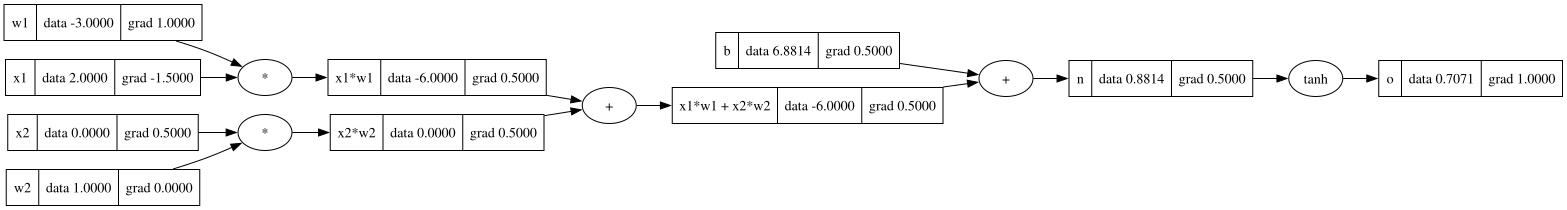

In [4]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

draw_dot(o)

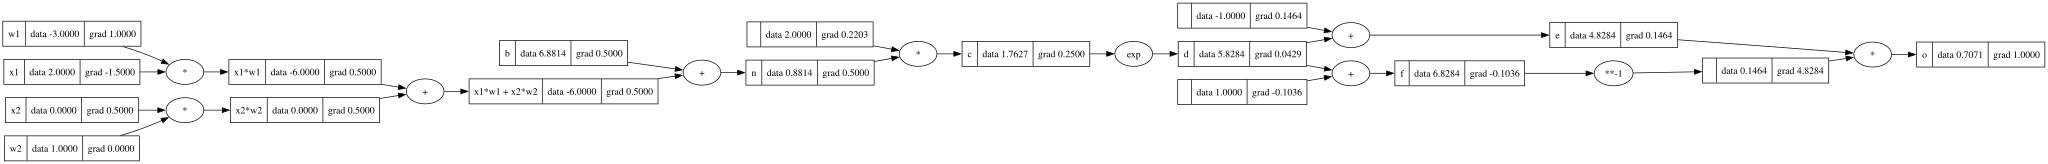

In [5]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

#    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)

c = 2*n; c.label = 'c'
d = c.exp(); d.label = 'd'
e = d - 1; e.label = 'e'

f = d + 1; f.label = 'f'

o = e/f; o.label = 'o'
o.backward()

draw_dot(o)

In [6]:
import torch

In [7]:
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print('result = ', o.data.item())
o.backward()

print('---')
print('x2 = ', x2.grad.item())
print('w2 = ', w2.grad.item())
print('x1 = ', x1.grad.item())
print('w1 = ', w1.grad.item())

result =  0.7071066904050358
---
x2 =  0.5000001283844369
w2 =  0.0
x1 =  -1.5000003851533106
w1 =  1.0000002567688737


In [8]:
o

tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [9]:
import random

class Neuron:
  
  def __init__(self, nin): #number of inputs
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))
  
  def __call__(self, x):
    # w * x[0] + w*x[1] + b
    raw_activation = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = raw_activation.tanh()
    return out

  def parameters(self):
      return self.w + [self.b] # this returns a list []

class Layer:
  
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  
  def __call__(self, x):
    outs = [n(x) for n in self.neurons] # return [out0, out1]
    return outs[0] if len(outs) == 1 else outs
  
  def parameters(self):
      return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  
  def __init__(self, nin, nouts): #nouts - each layer length (nin is the first one)
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
      return [p for layer in self.layers for p in layer.parameters()]

In [10]:
x = [2.0, 3.0, -1.0]
mlp = MLP(3, [4, 4, 1])
mlp(x)

Value(data=-0.8778997221800159)

In [11]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] #desired results
ypred = [mlp(x) for x in xs]


# mean squered error loss? why dont we just abs() the error why do we squere wtf
loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)]) # y - groung truth; yout - outputs; ys - desired results; ypred - predictions;
loss.backward()
loss

Value(data=7.02263316330542)

In [12]:
for i in range(20):

    #forward pass
    ypred = [mlp(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backward pass
    params = mlp.parameters()

    for p in params: p.grad = 0.0

    loss.backward()

    for p in params: p.data += -0.5*p.grad

    print(f'{i}: {loss.data}')
    

0: 7.02263316330542
1: 4.373151663755406
2: 2.140127901424787
3: 0.0063880553935475835
4: 0.005149103523082161
5: 0.004368940272976395
6: 0.003819417044676274
7: 0.0034058358199762794
8: 0.003080625234164117
9: 0.0028167903917754003
10: 0.002597661301268461
11: 0.002412286588805819
12: 0.002253124182896952
13: 0.002114783439225462
14: 0.0019932940575990462
15: 0.0018856584787419373
16: 0.0017895659130807296
17: 0.001703203032306857
18: 0.0016251248289606255
19: 0.0015541642230568202


In [17]:
# goal 0 loss
# if the gradient is negative -> increase the weight
# if the gradient is positive -> decrease the weight

ypred

[Value(data=0.9819552194217336),
 Value(data=-0.9897943589430679),
 Value(data=-0.9707872909514648),
 Value(data=0.9835375385315036)]

In [18]:
ys

[1.0, -1.0, -1.0, 1.0]